# 🤖 Model Training — Fake Product Review Detection

This notebook is the **core of the project**. It takes the preprocessed data and builds a Logistic Regression classifier that can detect fake product reviews.

## Pipeline Overview

```
Raw CSV → Preprocessing → EDA → Train/Test Split → TF-IDF → Logistic Regression → Evaluation → Save Model
```

| Step | Description |
|------|-------------|
| 1 | Import libraries |
| 2 | Load & preprocess data |
| 3 | Exploratory Data Analysis (EDA) with visualizations |
| 4 | Train/Test split (80/20, stratified) |
| 5 | TF-IDF vectorization (fitted on training data **only**) |
| 6 | Train Logistic Regression with cross-validation |
| 7 | Evaluate: accuracy, precision, recall, F1, confusion matrix |
| 8 | Hyperparameter tuning (only if accuracy < 87%) |
| 9 | Save model & vectorizer |

---

## 1. Import Libraries

We use:
- **pandas / numpy** — data manipulation
- **matplotlib / seaborn** — visualization
- **scikit-learn** — TF-IDF, Logistic Regression, evaluation metrics
- **joblib** — saving the trained model to disk

In [1]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)
import joblib

warnings.filterwarnings('ignore')

# Make plots display inline in the notebook
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


## 2. Configuration

Set up paths and constants used throughout the notebook.

| Parameter | Value | Purpose |
|-----------|-------|---------|
| `RANDOM_STATE` | 42 | Ensures reproducible results |
| `TEST_SIZE` | 0.2 | 80% training, 20% testing |
| `TARGET_ACCURACY` | 0.87 | Minimum acceptable accuracy |

In [2]:
# ── Configuration ──
RANDOM_STATE = 42
TEST_SIZE = 0.2
TARGET_ACCURACY = 0.87

# ── Paths (relative to notebook location in src/) ──
PROJECT_DIR = os.path.abspath("..")
DATA_PATH = os.path.join(PROJECT_DIR, "data", "fake_reviews_dataset.csv")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
MODEL_PATH = os.path.join(MODELS_DIR, "logistic_regression_model.pkl")
VECTORIZER_PATH = os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl")
CONFUSION_MATRIX_PATH = os.path.join(RESULTS_DIR, "confusion_matrix.png")
METRICS_PATH = os.path.join(RESULTS_DIR, "metrics.txt")

# ── Label mapping ──
LABEL_MAP = {'CG': 1, 'OR': 0}
LABEL_NAME_MAP = {1: 'Fake', 0: 'Genuine'}

# Ensure output directories exist
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print(f"📁 Project directory: {PROJECT_DIR}")
print(f"📁 Dataset path:     {DATA_PATH}")
print(f"📁 Models directory: {MODELS_DIR}")
print(f"📁 Results directory: {RESULTS_DIR}")

📁 Project directory: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection
📁 Dataset path:     c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\data\fake_reviews_dataset.csv
📁 Models directory: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\models
📁 Results directory: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\results


## 3. Load & Preprocess Data

We define the text cleaning function inline (same as `preprocess.py`) and load the dataset.

### 3.1 Text Cleaning Function

In [3]:
def clean_text(text):
    """Clean a single review text string."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)  # Remove URLs
    text = re.sub(r'<.*?>', '', text)               # Remove HTML tags
    text = re.sub(r'[^a-z0-9\s]', '', text)        # Remove punctuation
    text = re.sub(r'\s+', ' ', text).strip()       # Remove extra whitespace
    return text

print("✅ clean_text() defined")
print(f"   Example: 'GREAT product!!!' → '{clean_text("GREAT product!!!")}'")

✅ clean_text() defined
   Example: 'GREAT product!!!' → 'great product'


### 3.2 Load and Clean the Dataset

In [4]:
# ── Load ──
print(f"📂 Loading dataset from: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print(f"   Loaded {len(df):,} rows and {len(df.columns)} columns.\n")

# ── Keep relevant columns ──
EXPECTED_COLUMNS = ['category', 'rating', 'label', 'text_']
df = df[EXPECTED_COLUMNS].copy()

# ── Handle missing values ──
missing_text = df['text_'].isnull().sum()
missing_label = df['label'].isnull().sum()
print(f"Missing text: {missing_text}, Missing labels: {missing_label}")
df = df.dropna(subset=['text_', 'label'])

# ── Remove duplicates ──
duplicates = df.duplicated(subset=['text_'], keep='first').sum()
print(f"Duplicate reviews: {duplicates}")
df = df.drop_duplicates(subset=['text_'], keep='first')

# ── Validate labels ──
valid_labels = set(LABEL_MAP.keys())
invalid_count = (~df['label'].isin(valid_labels)).sum()
print(f"Invalid labels: {invalid_count}")
df = df[df['label'].isin(valid_labels)]

# ── Clean text ──
print("\nCleaning review text...")
df['text_'] = df['text_'].apply(clean_text)

# ── Remove empty reviews ──
empty_count = (df['text_'].str.strip() == '').sum()
print(f"Empty reviews after cleaning: {empty_count}")
df = df[df['text_'].str.strip() != '']

# ── Map labels ──
df['label'] = df['label'].map(LABEL_MAP)
df['label_name'] = df['label'].map(LABEL_NAME_MAP)
df = df.reset_index(drop=True)

print(f"\n✅ Preprocessing complete!")
print(f"   Final shape: {df.shape}")
print(f"   Fake reviews:    {(df['label'] == 1).sum():,}")
print(f"   Genuine reviews: {(df['label'] == 0).sum():,}")

📂 Loading dataset from: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\data\fake_reviews_dataset.csv
   Loaded 40,432 rows and 4 columns.

Missing text: 0, Missing labels: 0
Duplicate reviews: 20
Invalid labels: 0

Cleaning review text...
Empty reviews after cleaning: 1

✅ Preprocessing complete!
   Final shape: (40411, 5)
   Fake reviews:    20,196
   Genuine reviews: 20,215


## 4. Exploratory Data Analysis (EDA)

Before training, let's understand the dataset through statistics and visualizations.

### 4.1 Basic Statistics

In [5]:
print(f"📋 Dataset Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"\n📋 Column Data Types:")
print(df.dtypes)
print(f"\n📋 Missing Values:")
print(df.isnull().sum())
print(f"\n📋 Duplicate Reviews: {df.duplicated(subset=['text_']).sum()}")

📋 Dataset Shape: 40,411 rows × 5 columns

📋 Column Data Types:
category          str
rating        float64
label           int64
text_             str
label_name        str
dtype: object

📋 Missing Values:
category      0
rating        0
label         0
text_         0
label_name    0
dtype: int64

📋 Duplicate Reviews: 20


### 4.2 Class Distribution

How many fake vs. genuine reviews do we have? A **balanced** dataset (close to 50/50) is ideal for classification.

📋 Class Distribution:
   Genuine: 20,215 (50.0%)
   Fake: 20,196 (50.0%)


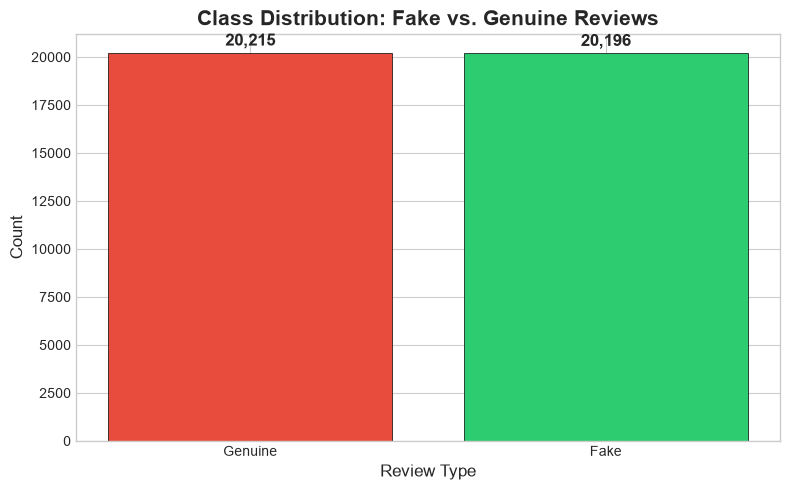

In [6]:
class_counts = df['label_name'].value_counts()

print("📋 Class Distribution:")
for label, count in class_counts.items():
    pct = count / len(df) * 100
    print(f"   {label}: {count:,} ({pct:.1f}%)")

# ── Visualization ──
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#e74c3c', '#2ecc71']  # Red = Fake, Green = Genuine
bars = ax.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black', linewidth=0.5)
ax.set_title('Class Distribution: Fake vs. Genuine Reviews', fontsize=15, fontweight='bold')
ax.set_xlabel('Review Type', fontsize=12)
ax.set_ylabel('Count', fontsize=12)

for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
            f'{count:,}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 4.3 Review Length Analysis

Do fake reviews tend to be shorter or longer than genuine ones? This can reveal linguistic differences.

In [7]:
# Calculate review lengths
df['review_length'] = df['text_'].str.len()
df['word_count'] = df['text_'].str.split().str.len()

print("📋 Review Length (characters):")
print(f"   Mean:   {df['review_length'].mean():.0f}")
print(f"   Median: {df['review_length'].median():.0f}")
print(f"   Min:    {df['review_length'].min()}")
print(f"   Max:    {df['review_length'].max()}")

print(f"\n📋 Word Count:")
print(f"   Mean:   {df['word_count'].mean():.0f}")
print(f"   Median: {df['word_count'].median():.0f}")
print(f"   Min:    {df['word_count'].min()}")
print(f"   Max:    {df['word_count'].max()}")

print(f"\n📋 Average Review Length by Class:")
for label_name in ['Fake', 'Genuine']:
    subset = df[df['label_name'] == label_name]
    print(f"   {label_name}: {subset['review_length'].mean():.0f} chars, {subset['word_count'].mean():.0f} words")

📋 Review Length (characters):
   Mean:   338
   Median: 191
   Min:    4
   Max:    2088

📋 Word Count:
   Mean:   67
   Median: 38
   Min:    1
   Max:    373

📋 Average Review Length by Class:
   Fake: 294 chars, 61 words
   Genuine: 382 chars, 73 words


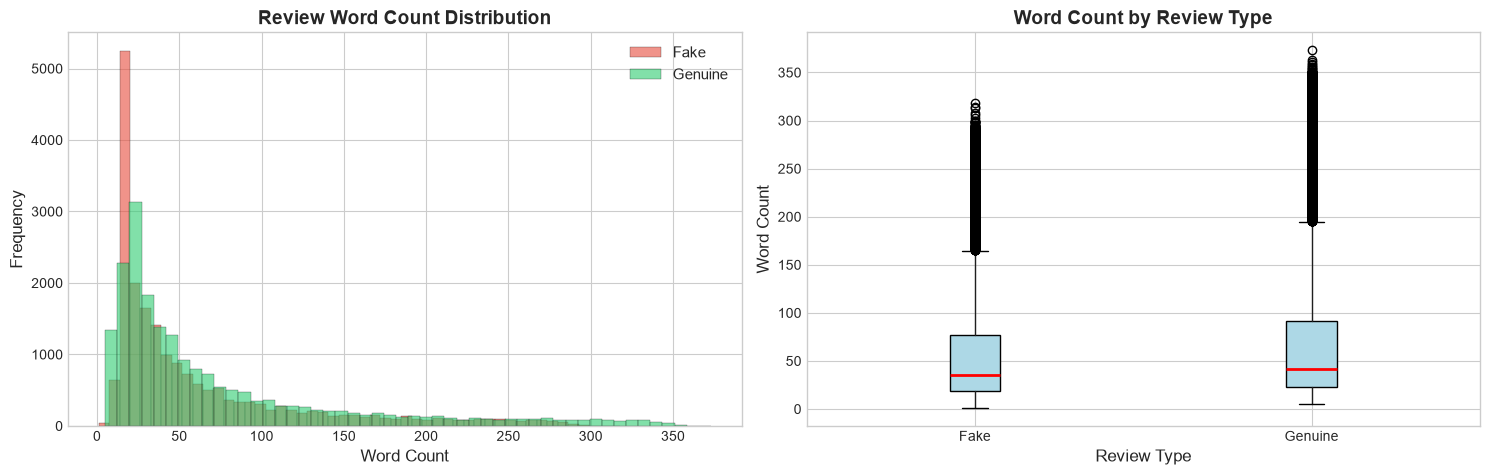

In [8]:
# ── Word Count Distribution by Class ──
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

colors = ['#e74c3c', '#2ecc71']

# Histogram
for label_name, color in zip(['Fake', 'Genuine'], colors):
    subset = df[df['label_name'] == label_name]
    axes[0].hist(subset['word_count'], bins=50, alpha=0.6, label=label_name,
                 color=color, edgecolor='black', linewidth=0.3)
axes[0].set_title('Review Word Count Distribution', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Word Count', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].legend(fontsize=11)

# Box plot
df.boxplot(column='word_count', by='label_name', ax=axes[1],
           patch_artist=True,
           boxprops=dict(facecolor='lightblue'),
           medianprops=dict(color='red', linewidth=2))
axes[1].set_title('Word Count by Review Type', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Review Type', fontsize=12)
axes[1].set_ylabel('Word Count', fontsize=12)
plt.suptitle('')  # Remove auto-generated title

plt.tight_layout()
plt.show()

### 4.4 Category Distribution

How are reviews distributed across product categories?

📋 Reviews per Category:
   Kindle_Store_5: 4,727
   Books_5: 4,369
   Pet_Supplies_5: 4,251
   Home_and_Kitchen_5: 4,055
   Electronics_5: 3,988
   Sports_and_Outdoors_5: 3,943
   Tools_and_Home_Improvement_5: 3,858
   Clothing_Shoes_and_Jewelry_5: 3,844
   Toys_and_Games_5: 3,791
   Movies_and_TV_5: 3,585


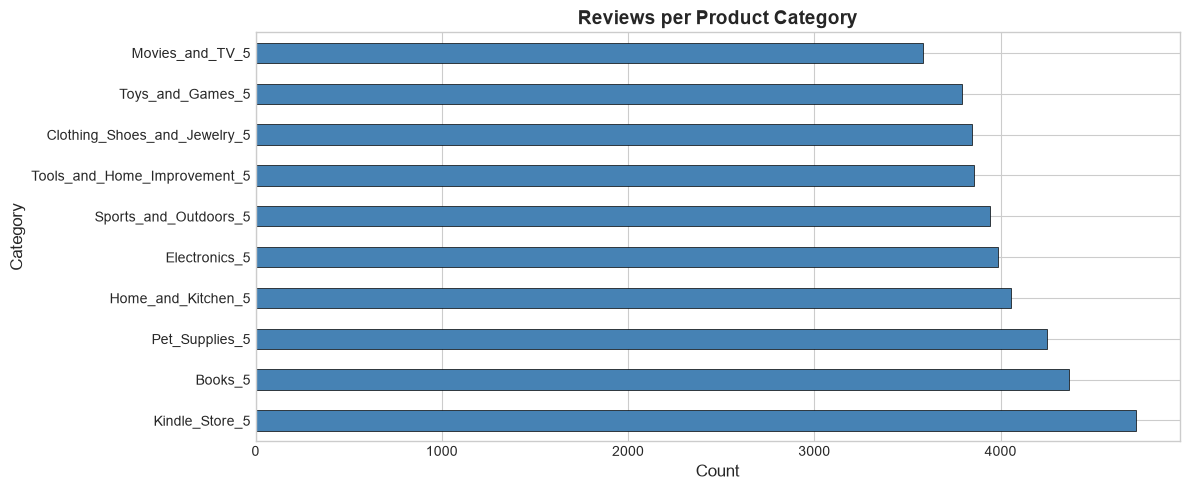

In [9]:
cat_counts = df['category'].value_counts()

print("📋 Reviews per Category:")
for cat, count in cat_counts.items():
    print(f"   {cat}: {count:,}")

# ── Visualization ──
fig, ax = plt.subplots(figsize=(12, 5))
cat_counts.plot(kind='barh', color='steelblue', edgecolor='black', linewidth=0.5, ax=ax)
ax.set_title('Reviews per Product Category', fontsize=14, fontweight='bold')
ax.set_xlabel('Count', fontsize=12)
ax.set_ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

In [10]:
# Clean up temporary columns (not needed for training)
df.drop(columns=['review_length', 'word_count'], inplace=True, errors='ignore')
print("✅ EDA complete! Temporary columns removed.")

✅ EDA complete! Temporary columns removed.


---

## 5. Train/Test Split

We split the data into **80% training** and **20% testing** sets.

Key points:
- **`stratify=y`** — ensures both splits have the same ratio of Fake/Genuine reviews
- **`random_state=42`** — makes the split reproducible
- The **test set is kept untouched** until final evaluation (no data leakage)

In [11]:
X = df['text_']   # Features (review text)
y = df['label']    # Target (0 = Genuine, 1 = Fake)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y  # Maintain class balance in both splits
)

print(f"✂️  Train/Test Split Complete!")
print(f"\n   Training set: {len(X_train):,} reviews")
print(f"   Testing set:  {len(X_test):,} reviews")
print(f"\n   Training — Fake: {(y_train == 1).sum():,} ({(y_train == 1).mean()*100:.1f}%), Genuine: {(y_train == 0).sum():,} ({(y_train == 0).mean()*100:.1f}%)")
print(f"   Testing  — Fake: {(y_test == 1).sum():,} ({(y_test == 1).mean()*100:.1f}%), Genuine: {(y_test == 0).sum():,} ({(y_test == 0).mean()*100:.1f}%)")

✂️  Train/Test Split Complete!

   Training set: 32,328 reviews
   Testing set:  8,083 reviews

   Training — Fake: 16,156 (50.0%), Genuine: 16,172 (50.0%)
   Testing  — Fake: 4,040 (50.0%), Genuine: 4,043 (50.0%)


---

## 6. TF-IDF Vectorization

**TF-IDF** (Term Frequency–Inverse Document Frequency) converts text into numerical features that our model can understand.

### How TF-IDF Works

- **Term Frequency (TF)**: How often a word appears in a document
- **Inverse Document Frequency (IDF)**: How rare a word is across all documents
- **TF-IDF = TF × IDF**: Words that appear frequently in a document but rarely across all documents get high scores

### Our Configuration

| Parameter | Value | Why |
|-----------|-------|-----|
| `max_features` | 15,000 | Limits vocabulary size for efficiency |
| `ngram_range` | (1, 2) | Uses single words AND two-word phrases |
| `min_df` | 2 | Ignores extremely rare terms |
| `max_df` | 0.95 | Ignores terms that appear in >95% of documents |
| `sublinear_tf` | True | Uses `1 + log(TF)` instead of raw TF |

> ⚠️ **IMPORTANT**: The vectorizer is fitted **ONLY on training data**. Test data is only transformed using the already-fitted vectorizer. This prevents data leakage.

In [12]:
# ── Create TF-IDF Vectorizer ──
vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True,
    strip_accents='unicode',
)

# ── Fit on training data ONLY, then transform both ──
print("📝 Fitting TF-IDF on training data...")
X_train_tfidf = vectorizer.fit_transform(X_train)  # fit + transform
X_test_tfidf = vectorizer.transform(X_test)         # transform only (no fit!)

print(f"\n✅ TF-IDF Vectorization Complete!")
print(f"   Training matrix shape: {X_train_tfidf.shape}")
print(f"   Testing matrix shape:  {X_test_tfidf.shape}")
print(f"   Vocabulary size: {len(vectorizer.vocabulary_):,} terms")
print(f"\n   Sample features: {list(vectorizer.vocabulary_.keys())[:10]}")

📝 Fitting TF-IDF on training data...

✅ TF-IDF Vectorization Complete!
   Training matrix shape: (32328, 15000)
   Testing matrix shape:  (8083, 15000)
   Vocabulary size: 15,000 terms

   Sample features: ['absolutely', 'love', 'this', 'the', 'look', 'and', 'feel', 'of', 'print', 'color']


---

## 7. Train Logistic Regression

**Logistic Regression** is ideal for this task because:
- Works well with high-dimensional sparse data (TF-IDF features)
- Fast to train
- Provides probability estimates (how confident the prediction is)
- Simple and interpretable

### 7.1 Cross-Validation

Before final training, we run **5-fold cross-validation** on the training data to estimate how well the model generalizes.

In [13]:
# ── Create the model ──
model = LogisticRegression(
    C=1.0,              # Regularization strength (higher = less regularization)
    max_iter=1000,       # Maximum iterations for convergence
    random_state=RANDOM_STATE,
    solver='lbfgs',      # Good default solver
)

# ── Cross-validation ──
print("🤖 Running 5-fold cross-validation...")
cv_scores = cross_val_score(model, X_train_tfidf, y_train, cv=5, scoring='accuracy')

print(f"\n   CV Accuracy scores: {[f'{s:.4f}' for s in cv_scores]}")
print(f"   CV Mean Accuracy:   {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

🤖 Running 5-fold cross-validation...

   CV Accuracy scores: ['0.9321', '0.9366', '0.9332', '0.9268', '0.9313']
   CV Mean Accuracy:   0.9320 ± 0.0032


### 7.2 Train on Full Training Set

In [14]:
# ── Train on the full training set ──
print("🤖 Training on full training set...")
model.fit(X_train_tfidf, y_train)

train_accuracy = model.score(X_train_tfidf, y_train)
print(f"\n✅ Training complete!")
print(f"   Training Accuracy: {train_accuracy:.4f} ({train_accuracy * 100:.2f}%)")

🤖 Training on full training set...

✅ Training complete!
   Training Accuracy: 0.9575 (95.75%)


---

## 8. Model Evaluation

Now we evaluate the model on the **test set** (data it has never seen during training).

### Metrics Explained

| Metric | What It Measures |
|--------|------------------|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of reviews predicted as Fake, what % are actually Fake |
| **Recall** | Of actual Fake reviews, what % did we catch |
| **F1-Score** | Harmonic mean of Precision and Recall (balanced metric) |

### Confusion Matrix Explained

| | Predicted Genuine | Predicted Fake |
|---|---|---|
| **Actual Genuine** | True Negative (TN) ✅ | False Positive (FP) ❌ |
| **Actual Fake** | False Negative (FN) ❌ | True Positive (TP) ✅ |

In [15]:
# ── Predictions on test set ──
y_pred = model.predict(X_test_tfidf)

# ── Calculate metrics ──
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("📈 Test Set Results:")
print(f"┌─────────────────────────────┐")
print(f"│ Accuracy:   {accuracy:.4f}          │")
print(f"│ Precision:  {precision:.4f}          │")
print(f"│ Recall:     {recall:.4f}          │")
print(f"│ F1-Score:   {f1:.4f}          │")
print(f"└─────────────────────────────┘")

if accuracy >= TARGET_ACCURACY:
    print(f"\n✅ Accuracy ({accuracy:.4f}) meets the target (>{TARGET_ACCURACY})!")
else:
    print(f"\n⚠️  Accuracy ({accuracy:.4f}) is below the target ({TARGET_ACCURACY}). Tuning may be needed.")

📈 Test Set Results:
┌─────────────────────────────┐
│ Accuracy:   0.9393          │
│ Precision:  0.9455          │
│ Recall:     0.9322          │
│ F1-Score:   0.9388          │
└─────────────────────────────┘

✅ Accuracy (0.9393) meets the target (>0.87)!


In [16]:
# ── Classification Report ──
target_names = ['Genuine (OR)', 'Fake (CG)']
print("📋 Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=target_names))

📋 Classification Report:

              precision    recall  f1-score   support

Genuine (OR)       0.93      0.95      0.94      4043
   Fake (CG)       0.95      0.93      0.94      4040

    accuracy                           0.94      8083
   macro avg       0.94      0.94      0.94      8083
weighted avg       0.94      0.94      0.94      8083



📊 Confusion Matrix Breakdown:
   True Negatives  (Genuine → Genuine): 3,826
   False Positives (Genuine → Fake):    217
   False Negatives (Fake → Genuine):    274
   True Positives  (Fake → Fake):       3,766

📊 Confusion matrix saved to: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\results\confusion_matrix.png


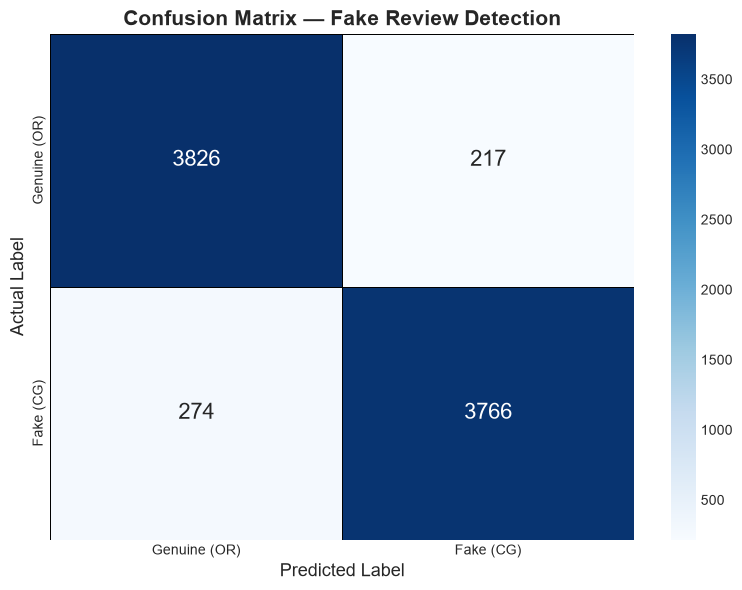

In [17]:
# ── Confusion Matrix ──
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("📊 Confusion Matrix Breakdown:")
print(f"   True Negatives  (Genuine → Genuine): {tn:,}")
print(f"   False Positives (Genuine → Fake):    {fp:,}")
print(f"   False Negatives (Fake → Genuine):    {fn:,}")
print(f"   True Positives  (Fake → Fake):       {tp:,}")

# ── Visualization ──
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names,
    ax=ax,
    annot_kws={'size': 16},
    linewidths=0.5,
    linecolor='black',
)
ax.set_xlabel('Predicted Label', fontsize=13)
ax.set_ylabel('Actual Label', fontsize=13)
ax.set_title('Confusion Matrix — Fake Review Detection', fontsize=15, fontweight='bold')
plt.tight_layout()

# Save
plt.savefig(CONFUSION_MATRIX_PATH, dpi=150, bbox_inches='tight')
print(f"\n📊 Confusion matrix saved to: {CONFUSION_MATRIX_PATH}")
plt.show()

### 8.1 Save Metrics to File

In [18]:
# ── Save metrics to text file ──
report = classification_report(y_test, y_pred, target_names=target_names)

with open(METRICS_PATH, 'w') as f:
    f.write("=" * 50 + "\n")
    f.write("Fake Product Review Detection — Evaluation Metrics\n")
    f.write("=" * 50 + "\n\n")
    f.write(f"Accuracy:   {accuracy:.4f} ({accuracy * 100:.2f}%)\n")
    f.write(f"Precision:  {precision:.4f} ({precision * 100:.2f}%)\n")
    f.write(f"Recall:     {recall:.4f} ({recall * 100:.2f}%)\n")
    f.write(f"F1-Score:   {f1:.4f} ({f1 * 100:.2f}%)\n\n")
    f.write(f"Confusion Matrix:\n")
    f.write(f"  True Negatives  (Genuine → Genuine): {tn}\n")
    f.write(f"  False Positives (Genuine → Fake):    {fp}\n")
    f.write(f"  False Negatives (Fake → Genuine):    {fn}\n")
    f.write(f"  True Positives  (Fake → Fake):       {tp}\n\n")
    f.write(f"Classification Report:\n{report}\n")

print(f"📄 Metrics saved to: {METRICS_PATH}")

📄 Metrics saved to: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\results\metrics.txt


---

## 9. Hyperparameter Tuning (If Needed)

If the baseline accuracy is **below 87%**, this cell uses `GridSearchCV` to find better parameters.

> **Note**: If the baseline already meets the target, this cell will skip tuning.

In [19]:
if accuracy < TARGET_ACCURACY:
    from sklearn.pipeline import Pipeline
    
    print(f"⚠️  Accuracy ({accuracy:.4f}) is below target ({TARGET_ACCURACY}). Starting tuning...\n")
    
    pipeline = Pipeline([
        ('tfidf', TfidfVectorizer(min_df=2, max_df=0.95, sublinear_tf=True, strip_accents='unicode')),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, solver='lbfgs')),
    ])
    
    param_grid = {
        'tfidf__max_features': [10000, 20000, 30000],
        'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
        'clf__C': [0.5, 1.0, 5.0, 10.0],
    }
    
    grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
    grid_search.fit(X_train, y_train)
    
    print(f"\n✅ Best parameters: {grid_search.best_params_}")
    print(f"   Best CV Accuracy: {grid_search.best_score_:.4f}")
    
    # Use the best model
    best_pipeline = grid_search.best_estimator_
    vectorizer = best_pipeline.named_steps['tfidf']
    model = best_pipeline.named_steps['clf']
    X_test_tfidf = vectorizer.transform(X_test)
    
    # Re-evaluate
    y_pred = model.predict(X_test_tfidf)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"   New Test Accuracy: {accuracy:.4f}")
else:
    print(f"✅ Accuracy ({accuracy:.4f}) already meets the target (>{TARGET_ACCURACY}). No tuning needed!")

✅ Accuracy (0.9393) already meets the target (>0.87). No tuning needed!


---

## 10. Save Model & Vectorizer

We save both the trained model and the TF-IDF vectorizer using **joblib**. This allows us to:
- Make predictions later without retraining
- Use the same model in the web app (`app.py`) and CLI (`predict.py`)

In [20]:
# ── Save model ──
joblib.dump(model, MODEL_PATH)
print(f"📦 Model saved to: {MODEL_PATH}")

# ── Save vectorizer ──
joblib.dump(vectorizer, VECTORIZER_PATH)
print(f"📦 Vectorizer saved to: {VECTORIZER_PATH}")

print(f"\n✅ Both artifacts saved successfully!")
print(f"   Model size:      {os.path.getsize(MODEL_PATH) / 1024:.1f} KB")
print(f"   Vectorizer size: {os.path.getsize(VECTORIZER_PATH) / 1024:.1f} KB")

📦 Model saved to: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\models\logistic_regression_model.pkl
📦 Vectorizer saved to: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\models\tfidf_vectorizer.pkl

✅ Both artifacts saved successfully!
   Model size:      118.0 KB
   Vectorizer size: 561.5 KB


---

## ✅ Training Complete!

### Summary

In [21]:
print("═" * 60)
print("  ✅ TRAINING COMPLETE!")
print("═" * 60)
print(f"\n  Final Accuracy: {accuracy * 100:.2f}%")
print(f"\n  Saved files:")
print(f"    📦 Model:            {MODEL_PATH}")
print(f"    📦 Vectorizer:       {VECTORIZER_PATH}")
print(f"    📊 Confusion Matrix: {CONFUSION_MATRIX_PATH}")
print(f"    📄 Metrics:          {METRICS_PATH}")
print(f"\n  Next steps:")
print(f"    → Run predict.ipynb to test predictions")
print(f"    → Run test.ipynb for comprehensive model testing")
print(f"    → Run 'streamlit run app.py' for the web interface")

════════════════════════════════════════════════════════════
  ✅ TRAINING COMPLETE!
════════════════════════════════════════════════════════════

  Final Accuracy: 93.93%

  Saved files:
    📦 Model:            c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\models\logistic_regression_model.pkl
    📦 Vectorizer:       c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\models\tfidf_vectorizer.pkl
    📊 Confusion Matrix: c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\results\confusion_matrix.png
    📄 Metrics:          c:\Users\ayush\OneDrive\Desktop\Project\fake-product-review-detection\results\metrics.txt

  Next steps:
    → Run predict.ipynb to test predictions
    → Run test.ipynb for comprehensive model testing
    → Run 'streamlit run app.py' for the web interface
